In [2]:
import sys
sys.path.append('/glade/u/home/manishrv/documents/croc/dev/CrocoLens')
%load_ext autoreload
%autoreload 2
from CrocoLens.regional_domain import RegionalDomain
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from regional_mom6 import regridding as rgd


In [ ]:
# cesm_surface_data = xr.open_mfdataset("/glade/u/home/manishrv/scratch/archive/gustavo-glorys-2/ocn/hist/*sfc*")
# glorys_daily_data = xr.open_mfdataset("/glade/campaign/collections/rda/data/d010049/2000/mercatorglorys12v1_gl12_mean_20000*.nc")
cesm_large = xr.open_dataset("/glade/u/home/manishrv/scratch/archive/gustavo-glorys-2/ocn/hist/gustavo-glorys-2.mom6.h.sfc.2000-01.nc")
hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")

In [20]:
cesm_in = xr.open_dataset("/glade/derecho/scratch/manishrv/temp/cesm_surface_data_in.nc")
glorys_in = xr.open_dataset("/glade/derecho/scratch/manishrv/temp/glorys_daily_data_in.nc")


In [ ]:
# from regional_mom6 import regridding as rgd
# cesm_in["longitude"] = cesm_in["xh"]
# cesm_in["latitude"] = cesm_in["yh"]
# regridder = rgd.create_regridder(glorys_in, cesm_in,locstream_out=False)
# glorys_in_regridded = regridder(glorys_in)
# glorys_in_regridded.to_netcdf("/glade/derecho/scratch/manishrv/temp/glorys_regridded.nc")

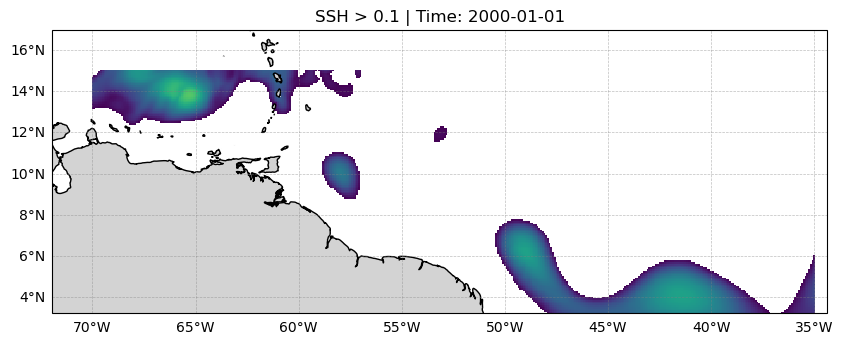

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.animation as animation
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
# import numpy as np

# # Load your dataset

# dataset = glorys_in
# ssh = dataset["zos"]

# # Threshold value for high SSH (adjust as needed)
# threshold = 0.1
# ssh_masked = ssh.where(ssh > threshold)

# # Set up the figure and axis with cartopy
# fig = plt.figure(figsize=(10, 5))
# ax = plt.axes(projection=ccrs.PlateCarree())

# ax.set_extent(
#     [cesm_in.xh.min() - 2, cesm_in.xh.max() + 2, cesm_in.yh.min() - 2, cesm_in.yh.max() + 2],
#     crs=ccrs.PlateCarree(),
# )
# ax.add_feature(cfeature.LAND, fc="lightgray")
# ax.coastlines(resolution="10m")
# gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
# gl.top_labels = gl.right_labels = False

# # Create meshgrid of coordinates
# lon, lat = np.meshgrid(dataset.longitude, dataset.latitude)

# # Plot placeholder
# plot = ax.pcolormesh(lon, lat, ssh_masked.isel(time=0), cmap="viridis", transform=ccrs.PlateCarree())

# # Title text
# title = ax.set_title("")

# # Animation function
# def update(frame):
#     plot.set_array(ssh_masked.isel(time=frame).values.ravel())
#     title.set_text(f"SSH > {threshold} | Time: {str(dataset.time.values[frame])[:10]}")
#     return plot, title

# # Create the animation
# ani = animation.FuncAnimation(fig, update, frames=92, blit=False)

# # Save or show the animation
# ani.save("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/plots/glorys_vs_cesm/in_out/high_ssh_animation_glorys.mp4", fps=10, dpi=150)
# # plt.show()  # uncomment this to view live instead


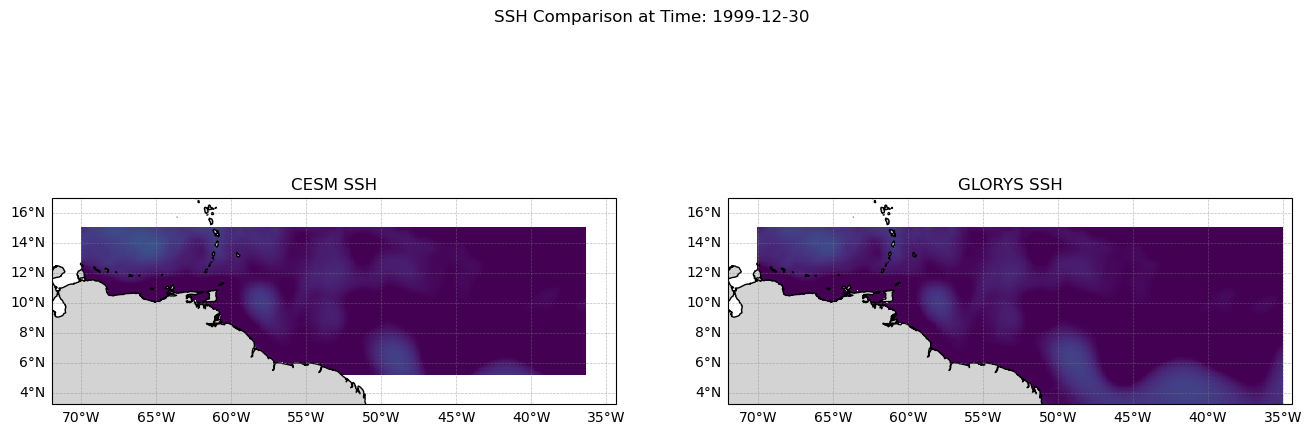

In [ ]:
# # Set up the figure with two axes
# ssh_cesm = cesm_in["SSH"]
# ssh_glorys = glorys_in["zos"]
# fig, axs = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={'projection': ccrs.PlateCarree()})
# titles = ["CESM SSH", "GLORYS SSH"]

# for ax, title_text in zip(axs, titles):
#     ax.set_extent(
#         [cesm_in.xh.min() - 2, cesm_in.xh.max() + 2, cesm_in.yh.min() - 2, cesm_in.yh.max() + 2],
#         crs=ccrs.PlateCarree(),
#     )
#     ax.add_feature(cfeature.LAND, fc="lightgray")
#     ax.coastlines(resolution="10m")
#     gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
#     gl.top_labels = gl.right_labels = False
#     ax.set_title(title_text)

# lon, lat = np.meshgrid(cesm_in.xh, cesm_in.yh)
# lon_g, lat_g = np.meshgrid(glorys_in.longitude, glorys_in.latitude)

# # Initial plots
# plot_cesm = axs[0].pcolormesh(lon, lat, ssh_cesm.isel(time=0), cmap="viridis", transform=ccrs.PlateCarree(), vmin=0, vmax=1)
# plot_glorys = axs[1].pcolormesh(lon_g, lat_g, ssh_glorys.isel(time=0), cmap="viridis", transform=ccrs.PlateCarree(), vmin=0, vmax=1)

# # Shared title
# suptitle = fig.suptitle("")

# # Update function
# def update(frame):
#     plot_cesm.set_array(ssh_cesm.isel(time=frame).values.ravel())
#     plot_glorys.set_array(ssh_glorys.isel(time=frame).values.ravel())
#     time_str = str(cesm_in.time.values[frame])[:10]
#     suptitle.set_text(f"SSH Comparison at Time: {time_str}")
#     return plot_cesm, plot_glorys, suptitle

# # Animate
# ani = animation.FuncAnimation(fig, update, frames=60, blit=False)
# ani.save("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/plots/glorys_vs_cesm/in_out/high_ssh_animation_sidebyside.mp4", fps=10, dpi=150)


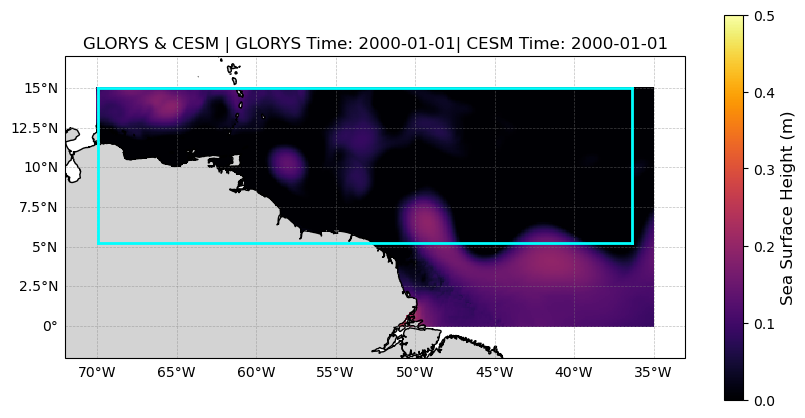

In [27]:

# Define domain edges
lon_min, lon_max = float(glorys_in.longitude.min()), float(glorys_in.longitude.max())
lat_min, lat_max = float(glorys_in.latitude.min()), float(glorys_in.latitude.max())

# GLORYS high SSH mask
# Find actual lat lon
# Read sample large File

lon_idx_start = int(np.where(cesm_large['xh'].values == cesm_in['xh'].values[0])[0][0])
lon_idx_end = int(np.where(cesm_large['xh'].values == cesm_in['xh'].values[-1])[0][0])
lat_idx_start = int(np.where(cesm_large['yh'].values == cesm_in['yh'].values[0])[0][0])
lat_idx_end = int(np.where(cesm_large['yh'].values == cesm_in['yh'].values[-1])[0][0])
# Go to hgrid, find actual lat lon meshes
t_points = rgd.get_hgrid_arakawa_c_points(hgrid, "t")
cesm_lon = t_points["tlon"][lat_idx_start:lat_idx_end+1, lon_idx_start:lon_idx_end+1]
cesm_lat = t_points["tlat"][lat_idx_start:lat_idx_end+1, lon_idx_start:lon_idx_end+1]

# Setup plot
fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([lon_min - 2, lon_max + 2, lat_min - 2, lat_max + 2], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False

# Grid
lon, lat = np.meshgrid(glorys_in.longitude, glorys_in.latitude)
plot = ax.pcolormesh(lon, lat, glorys_in["zos"].isel(time=0), cmap="inferno", transform=ccrs.PlateCarree(), vmin=0, vmax=0.5)
cesm_plot = ax.pcolormesh(
    cesm_lon, cesm_lat, cesm_in["SSH"].isel(time=0),
    cmap="inferno", shading="auto", transform=ccrs.PlateCarree(), vmin=0, vmax=0.5
)
cbar = plt.colorbar(cesm_plot)
cbar.set_label("Sea Surface Height (m)", fontsize=12)
lon_min, lon_max = float(cesm_in.xh.min()), float(cesm_in.xh.max())
lat_min, lat_max = float(cesm_in.yh.min()), float(cesm_in.yh.max())
# Draw curved CESM domain boundary
top    = cesm_lat[0, :],    cesm_lon[0, :]
bottom = cesm_lat[-1, :],   cesm_lon[-1, :]
left   = cesm_lat[:, 0],    cesm_lon[:, 0]
right  = cesm_lat[:, -1],   cesm_lon[:, -1]

ax.plot(top[1], top[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(bottom[1], bottom[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(left[1], left[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(right[1], right[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)

title = ax.set_title("")

def update(frame):
    plot.set_array(glorys_in["zos"].isel(time=frame).values.ravel())
    # Update CESM
    cesm_plot.set_array(cesm_in["SSH"].isel(time=frame+2).values.ravel())
    title.set_text(f"GLORYS & CESM | GLORYS Time: {str(glorys_in.time.values[frame])[:10]}| CESM Time: {str(cesm_in.time.values[frame+2])[:10]}")
    return plot, title

ani = animation.FuncAnimation(fig, update, frames=274, blit=False)

ani.save("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/plots/glorys_vs_cesm/in_out/glorys_into_cesm_domain_v2.mp4", fps=10, dpi=150)

In [21]:
cesm_out = xr.open_dataset("/glade/derecho/scratch/manishrv/temp/cesm_surface_data_ssh_large_out.nc")
glorys_out = xr.open_dataset("/glade/derecho/scratch/manishrv/temp/glorys_daily_data_ssh_large_out.nc")


In [ ]:
# boxes_cesm = {
#     "in": {
#         "lon_min": -70,
#         "lon_max": -35,
#         "lat_min": 0,
#         "lat_max": 15,
#     },
#     "out": {
#         "lon_min": -63,
#         "lon_max": -30,
#         "lat_min": 40,
#         "lat_max": 64,
#     },
# }
# boxes_glorys = {
#     "in": {
#         "lon_min": -70,
#         "lon_max": -35,
#         "lat_min": 0,
#         "lat_max": 15,
#     },
#     "out": {
#         "lon_min": -63,
#         "lon_max": -30,
#         "lat_min": 40,
#         "lat_max": 64,
#     },
# }

# box = "out"
# lon_min = boxes_cesm[box]["lon_min"]
# lon_max = boxes_cesm[box]["lon_max"]
# lat_min = boxes_cesm[box]["lat_min"]
# lat_max = boxes_cesm[box]["lat_max"]
# cesm_out = (cesm_surface_data.sel(xh=slice(lon_min, lon_max), yh=slice(lat_min, lat_max)))[["SSH"]]
# lon_min = boxes_glorys[box]["lon_min"]
# lon_max = boxes_glorys[box]["lon_max"]
# lat_min = boxes_glorys[box]["lat_min"]
# lat_max = boxes_glorys[box]["lat_max"]
# glorys_out = (glorys_daily_data.sel(longitude=slice(lon_min, lon_max), latitude=slice(lat_min, lat_max)))[["zos"]]

In [ ]:
# Find actual lat lon
# Read sample large File


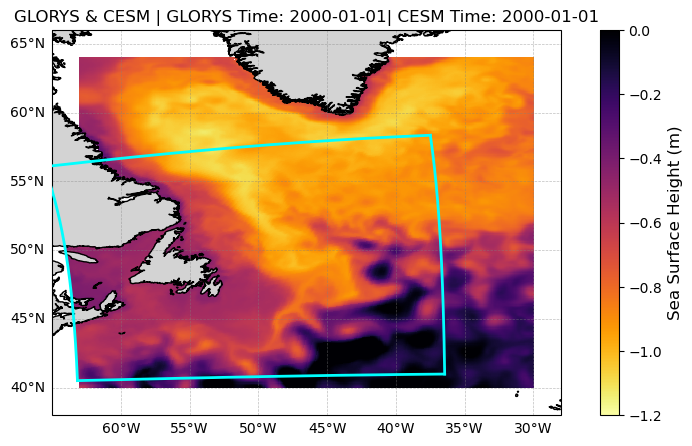

In [ ]:

lon_idx_start = int(np.where(cesm_large['xh'].values == cesm_out['xh'].values[0])[0][0])
lon_idx_end = int(np.where(cesm_large['xh'].values == cesm_out['xh'].values[-1])[0][0])
lat_idx_start = int(np.where(cesm_large['yh'].values == cesm_out['yh'].values[0])[0][0])
lat_idx_end = int(np.where(cesm_large['yh'].values == cesm_out['yh'].values[-1])[0][0])
t_points = rgd.get_hgrid_arakawa_c_points(hgrid, "t")
cesm_lon = t_points["tlon"][lat_idx_start:lat_idx_end+1, lon_idx_start:lon_idx_end+1]
cesm_lat = t_points["tlat"][lat_idx_start:lat_idx_end+1, lon_idx_start:lon_idx_end+1]

# Define domain edges
lon_min, lon_max = float(glorys_out.longitude.min()), float(glorys_out.longitude.max())
lat_min, lat_max = float(glorys_out.latitude.min()), float(glorys_out.latitude.max())


# Setup plot
fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([lon_min - 2, lon_max + 2, lat_min - 2, lat_max + 2], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, fc="lightgray")
ax.coastlines(resolution="10m")
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False

# Grid
lon, lat = np.meshgrid(glorys_out.longitude, glorys_out.latitude)
plot = ax.pcolormesh(lon, lat, glorys_out["zos"].isel(time=0), cmap="inferno_r", transform=ccrs.PlateCarree(), vmin=-1.2, vmax=0)
cesm_plot = ax.pcolormesh(
    cesm_lon, cesm_lat, cesm_out["SSH"].isel(time=2),
    cmap="inferno_r", shading="auto", transform=ccrs.PlateCarree(), vmin=-1.2, vmax=0
)
cbar = plt.colorbar(cesm_plot)
cbar.set_label("Sea Surface Height (m)", fontsize=12)
lon_min, lon_max = float(cesm_out.xh.min()), float(cesm_out.xh.max())
lat_min, lat_max = float(cesm_out.yh.min()), float(cesm_out.yh.max())
# Draw curved CESM domain boundary
top    = cesm_lat[0, :],    cesm_lon[0, :]
bottom = cesm_lat[-1, :],   cesm_lon[-1, :]
left   = cesm_lat[:, 0],    cesm_lon[:, 0]
right  = cesm_lat[:, -1],   cesm_lon[:, -1]

ax.plot(top[1], top[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(bottom[1], bottom[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(left[1], left[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)
ax.plot(right[1], right[0], color='cyan', linewidth=2, transform=ccrs.PlateCarree(), zorder=10)

title = ax.set_title("")

def update(frame):
    plot.set_array(glorys_out["zos"].isel(time=frame).values.ravel())
    # Update CESM
    cesm_plot.set_array(cesm_out["SSH"].isel(time=frame+2).values.ravel())
    title.set_text(f"GLORYS & CESM | GLORYS Time: {str(glorys_out.time.values[frame])[:10]}| CESM Time: {str(cesm_out.time.values[frame+2])[:10]}")
    return plot, title

ani = animation.FuncAnimation(fig, update, frames=274, blit=False)

ani.save("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/plots/glorys_vs_cesm/in_out/glorys_outof_cesm_domain_small.mp4", fps=10, dpi=150)

In [8]:
cesm_large = xr.open_dataset("/glade/u/home/manishrv/scratch/archive/gustavo-glorys-2/ocn/hist/gustavo-glorys-2.mom6.h.sfc.2000-12.nc")
cesm_large.time_bounds

<xarray.DataArray 'time_bounds' (time: 31, nbnd: 2)>
[62 values with dtype=datetime64[ns]]
Coordinates:
  * time     (time) datetime64[ns] 2000-11-29T12:00:00 ... 2000-12-29T12:00:00
  * nbnd     (nbnd) float64 1.0 2.0
Attributes:
    long_name:  time interval endpoints